# Harry Potter Sosyal Ağ Analizi

Bu notebook, `src/hpgraph` paketindeki fonksiyonları kullanarak ağı adım adım inceler.
Veri `data/` klasöründeki iki CSV dosyasından okunur; tüm hesaplar pakette olduğu için
notebook yalnızca **anlatım ve görselleştirme** katmanıdır.

**Araştırma soruları**
1. Ağın merkezinde kim var, köprü görevini kim görüyor?
2. Hogwarts evleri sosyal olarak kümeleniyor mu, yoksa topluluklar evlerden bağımsız mı?
3. Ağ ne kadar dayanıklı: kritik karakterler çıkarılınca ne olur?
4. Dostluk/düşmanlık ilişkileri yapısal olarak tutarlı mı (Heider dengesi)?

In [1]:
import sys
sys.path.insert(0, "../src")   # paket kurulu değilse (pip install -e . yapılmadıysa) çalışsın

import pandas as pd
import matplotlib.pyplot as plt
from hpgraph import build_graph, build_positive_graph
from hpgraph import metrics as M
from hpgraph import plots as P

pd.set_option("display.precision", 3)
G  = build_graph()            # tüm ilişkiler (friend, family, ally, enemy)
Gp = build_positive_graph()   # yalnızca dostça ilişkiler
pos = P.compute_layout(G)     # tüm çizimlerde aynı yerleşim

## 1. Veri ve ağ özeti

In [2]:
summary = M.network_summary(G)
pd.Series({k: v for k, v in summary.items() if k != "isolated"}, name="Değer").to_frame()

,Değer
nodes,43.000
edges,142.000
density,0.157
avg_degree,6.605
avg_clustering,0.632
transitivity,0.386
components,1.000
main_component_size,43.000
diameter,5.000
radius,3.000


In [3]:
pd.Series(M.relation_counts(G), name="Kenar sayısı").to_frame()

,Kenar sayısı
friend,40
family,31
ally,44
enemy,27


## 2. Ağın görünümü
Renk: Hogwarts evi. Düğüm boyutu: degree centrality.

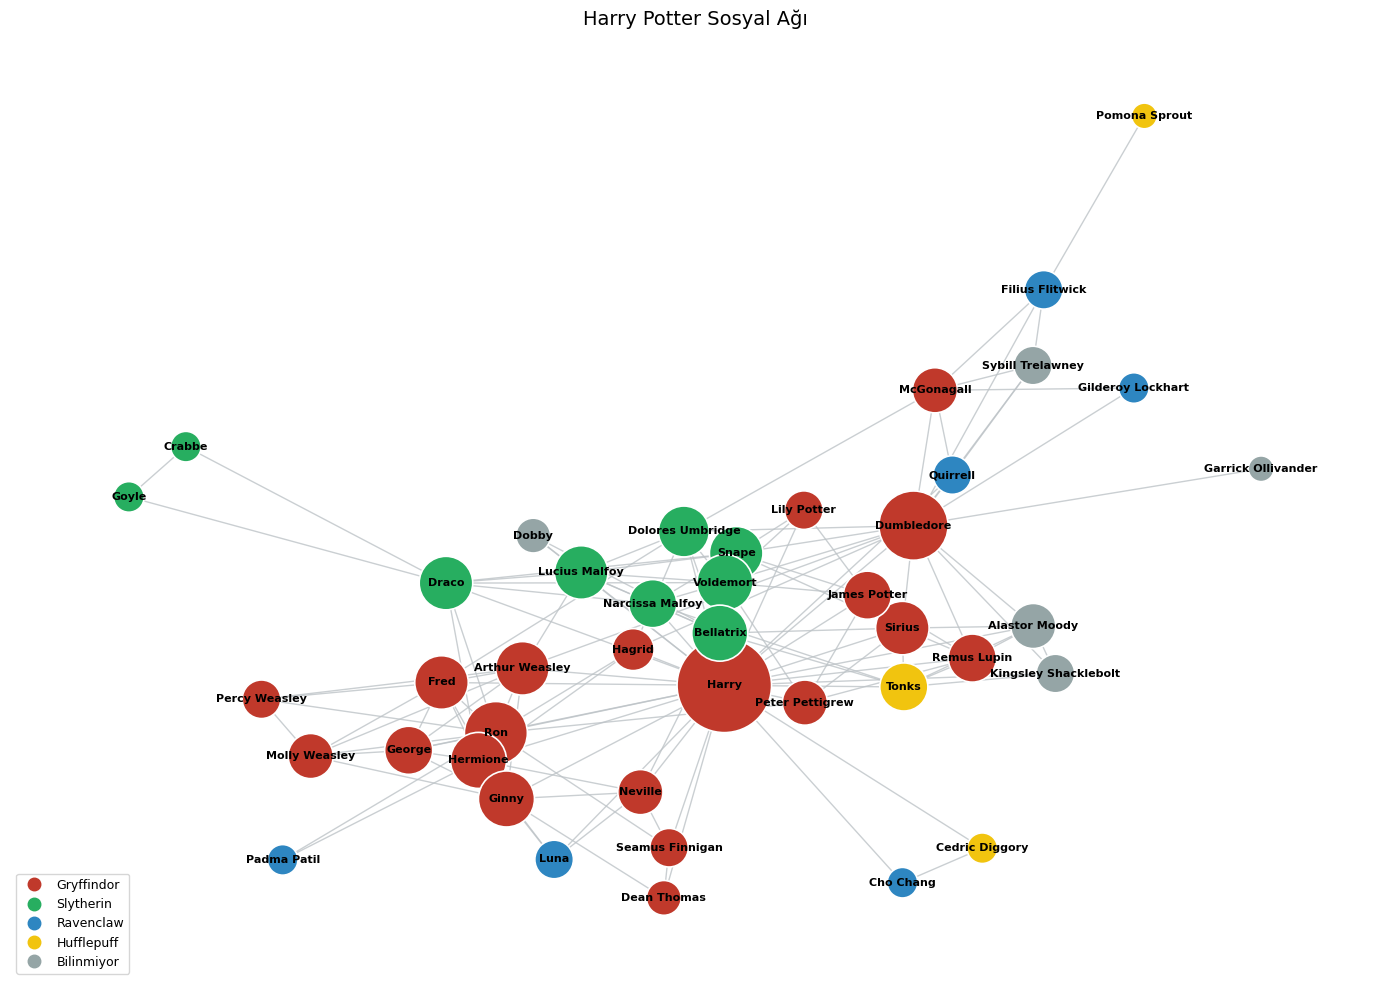

In [4]:
table = M.centrality_table(G)
sizes = {n: 200 + 6000 * table.loc[n, "degree_centrality"] for n in G}
P.plot_network(G, pos, sizes, "Harry Potter Sosyal Ağı");

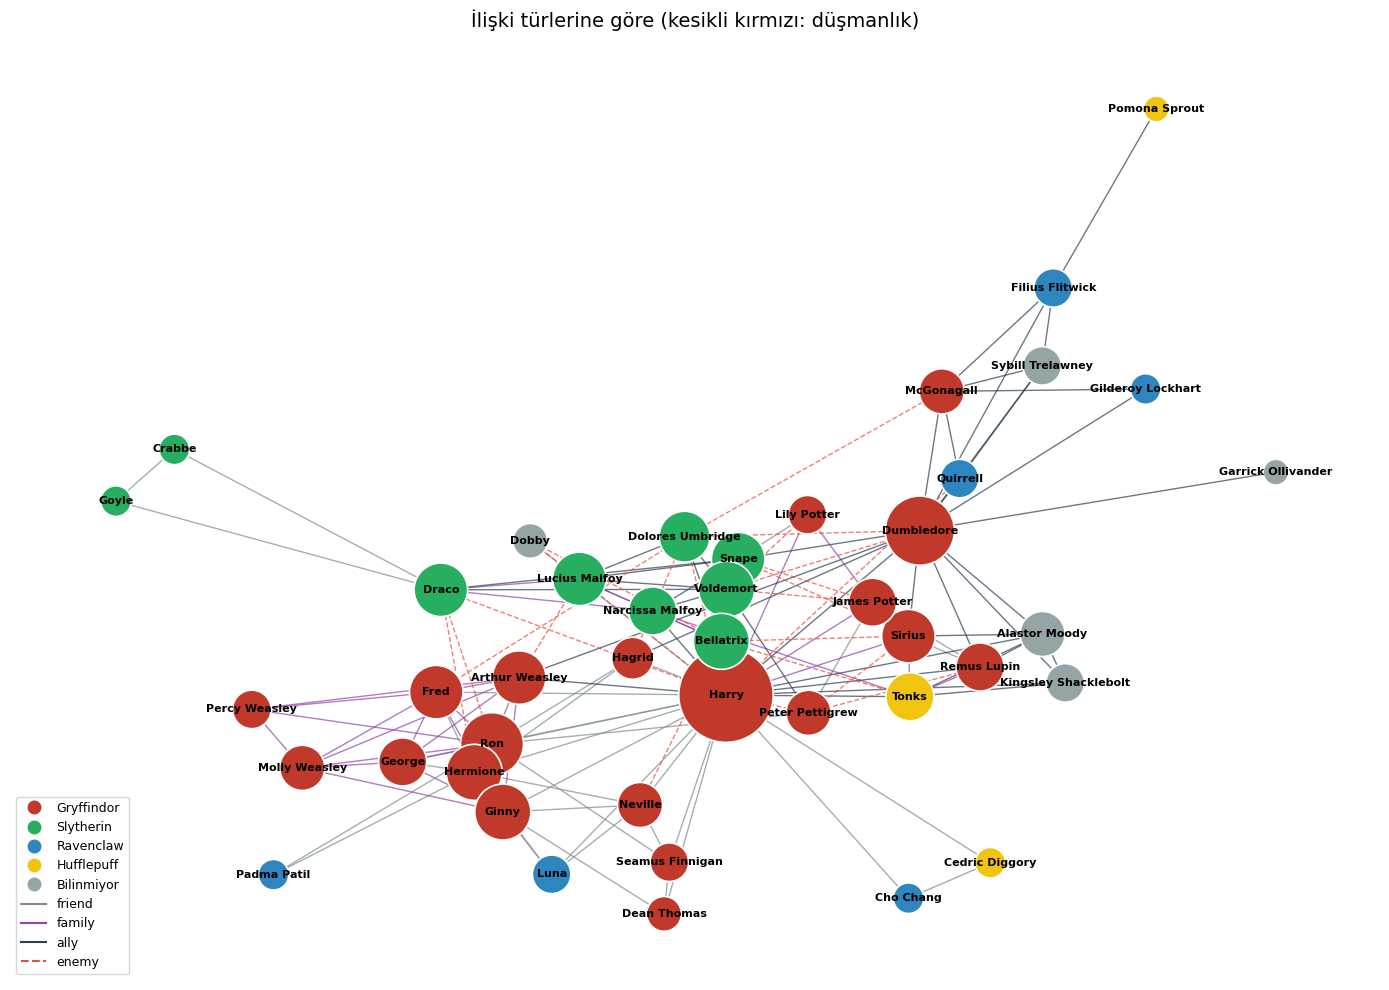

In [5]:
P.plot_network(G, pos, sizes, "İlişki türlerine göre (kesikli kırmızı: düşmanlık)", show_relations=True);

## 3. Merkezilik analizi
| Metrik | Soru |
|---|---|
| Degree | Kaç doğrudan bağlantısı var? |
| Closeness | Diğer herkese ortalama kaç adımda ulaşıyor? |
| Betweenness | En kısa yolların ne kadarı ondan geçiyor (köprü)? |
| Eigenvector | Bağlantıları ne kadar *önemli* düğümlere? |
| PageRank | Rastgele gezginin uğrama olasılığı |

In [6]:
table.head(10)

,house,degree,strength,degree_centrality,closeness,betweenness,eigenvector,pagerank,clustering,core_number
Harry,Gryffindor,31,63,0.738,0.778,0.484,0.473,0.102,0.181,5
Dumbledore,Gryffindor,16,32,0.381,0.592,0.239,0.228,0.061,0.200,5
Ron,Gryffindor,13,28,0.310,0.538,0.071,0.220,0.045,0.359,5
Hermione,Gryffindor,10,17,0.238,0.519,0.033,0.185,0.029,0.444,5
Ginny,Gryffindor,10,22,0.238,0.506,0.016,0.188,0.035,0.533,5
Voldemort,Slytherin,10,20,0.238,0.538,0.030,0.207,0.033,0.422,5
Bellatrix,Slytherin,10,19,0.238,0.494,0.012,0.202,0.031,0.444,5
Snape,Slytherin,9,16,0.214,0.532,0.024,0.194,0.027,0.472,5
Arthur Weasley,Gryffindor,9,18,0.214,0.538,0.047,0.188,0.029,0.528,5
Sirius,Gryffindor,9,21,0.214,0.519,0.010,0.188,0.034,0.556,5


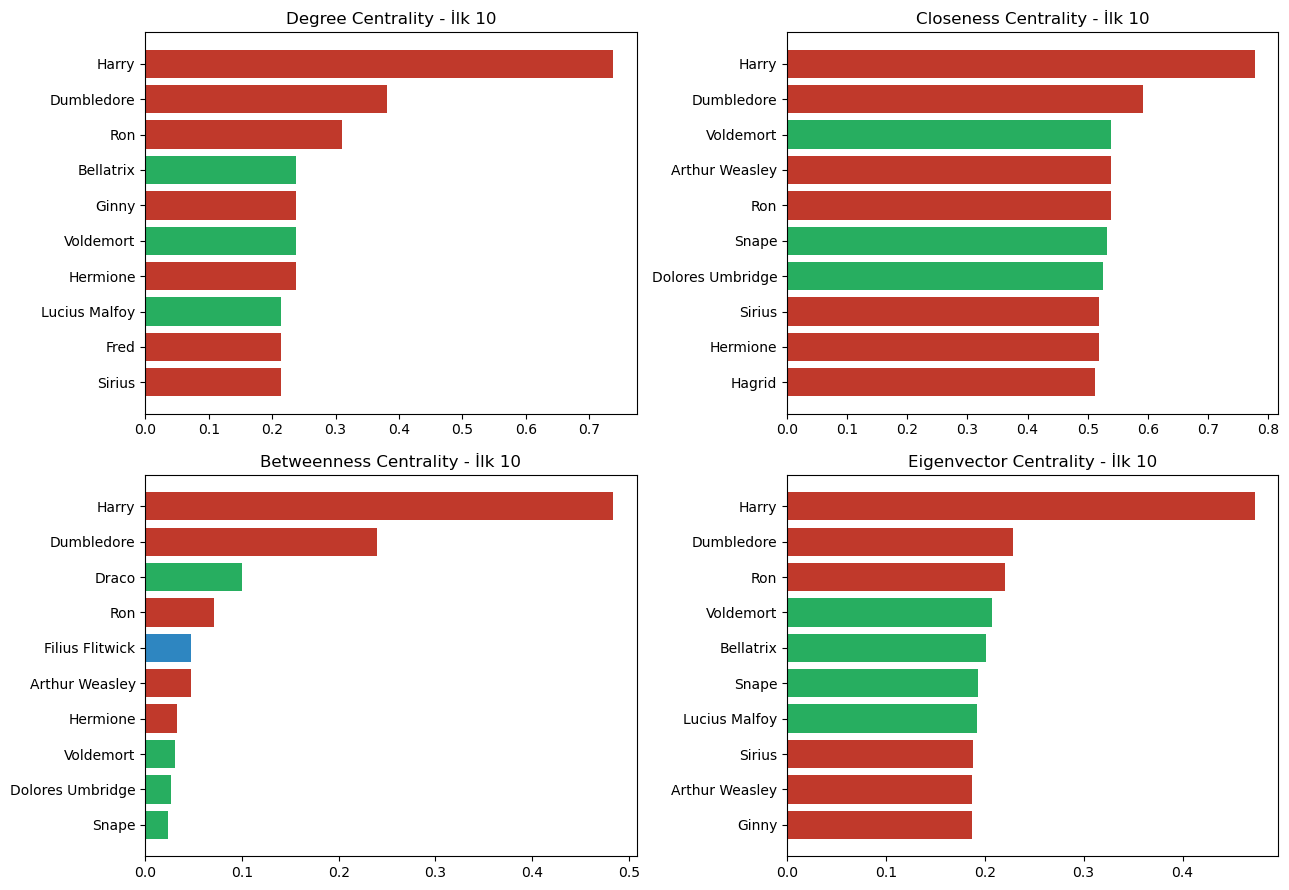

In [7]:
P.plot_centrality_panel(table);

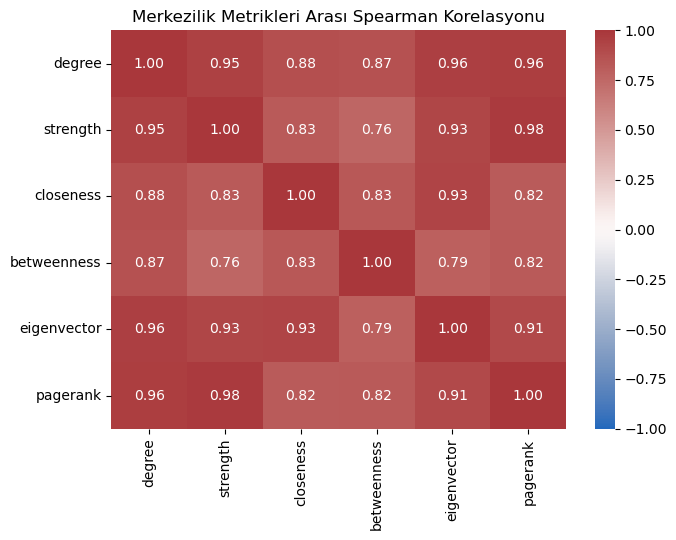

In [8]:
P.plot_correlation(M.centrality_correlation(table));

> **Önemli not:** Veri Harry'nin bakış açısıyla toplandığı için Harry'nin ağ üzerindeki yüksek skoru kısmen
> *örneklem yanlılığıdır* (ego-network etkisi). Sonuçlar bu çerçevede yorumlanmalıdır.

## 4. Yapısal kırılganlık: kesim noktaları ve köprüler

In [9]:
cuts, bridges = M.cut_vertices_and_bridges(G)
print("Kesim noktaları (çıkarılırsa ağ parçalanır):", cuts)
print("Köprü kenarlar:", bridges)

Kesim noktaları (çıkarılırsa ağ parçalanır): ['Draco', 'Dumbledore', 'Filius Flitwick', 'Harry']
Köprü kenarlar: [('Dumbledore', 'Garrick Ollivander'), ('Filius Flitwick', 'Pomona Sprout')]


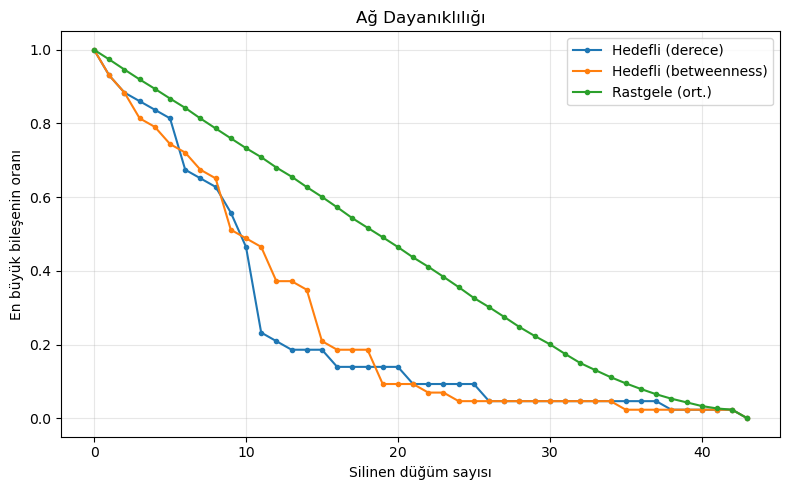

In [10]:
curves = [M.robustness_curve(G, s) for s in ("degree", "betweenness", "random")]
P.plot_robustness(curves);

## 5. Evler ve topluluklar

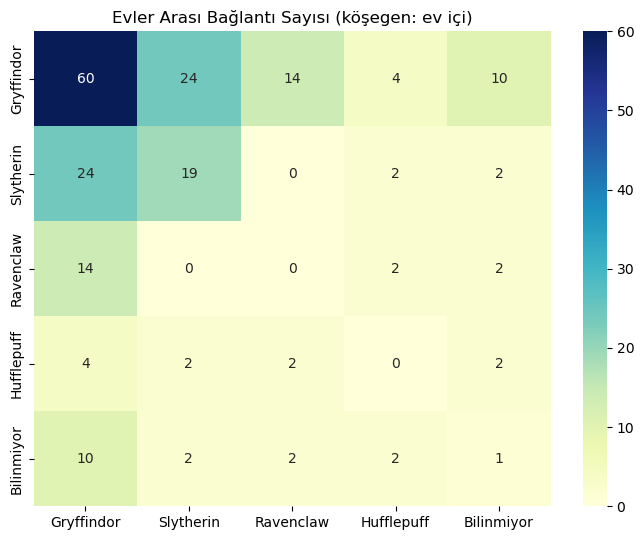

In [11]:
P.plot_house_heatmap(M.house_connection_matrix(G));

In [12]:
r = M.house_assortativity(Gp)
p = M.house_assortativity_pvalue(Gp)
print(f"Ev assortativity (dostça ağ): {r:.3f}   permütasyon p-değeri: {p:.4f}")

Ev assortativity (dostça ağ): 0.405   permütasyon p-değeri: 0.0005


Louvain modularity: 0.490   Ev bölümlemesi modularity: 0.227
NMI (topluluk vs. ev): 0.417
Topluluk 1 (11): Arthur Weasley, Fred, George, Ginny, Hermione, Luna, Molly Weasley, Neville, Padma Patil, Percy Weasley, Ron
Topluluk 2 (11): Alastor Moody, Cedric Diggory, Cho Chang, Dobby, Harry, James Potter, Kingsley Shacklebolt, Lily Potter, Remus Lupin, Sirius, Tonks
Topluluk 3 (10): Bellatrix, Crabbe, Dolores Umbridge, Draco, Goyle, Lucius Malfoy, Narcissa Malfoy, Peter Pettigrew, Snape, Voldemort
Topluluk 4 (9): Dumbledore, Filius Flitwick, Garrick Ollivander, Gilderoy Lockhart, Hagrid, McGonagall, Pomona Sprout, Quirrell, Sybill Trelawney
Topluluk 5 (2): Dean Thomas, Seamus Finnigan


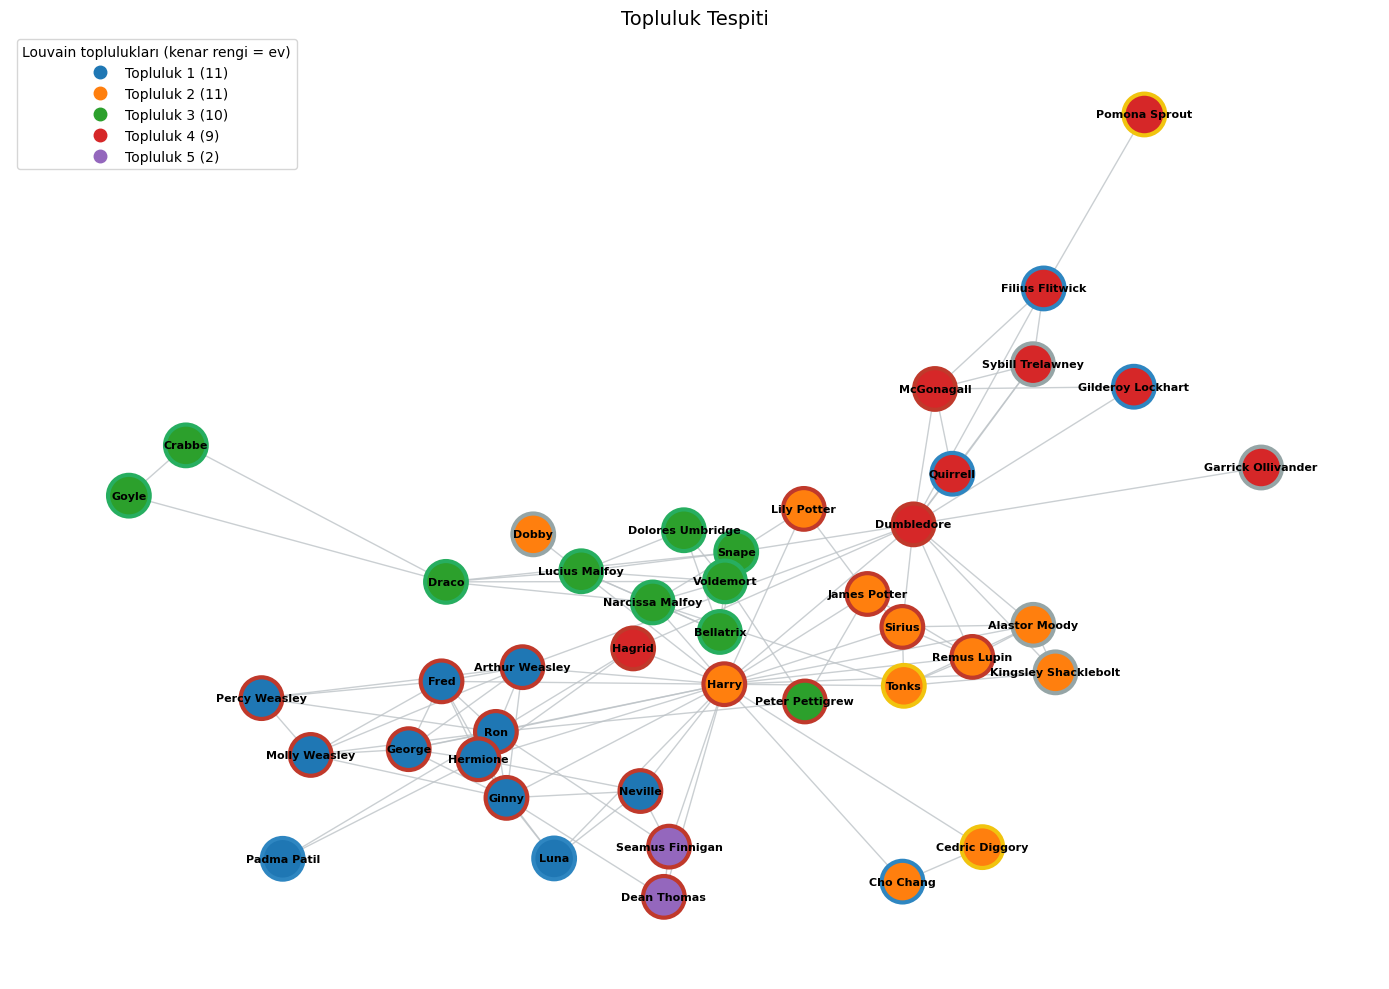

In [13]:
comms = M.detect_communities(Gp)
houses = M.house_partition(Gp)
print(f"Louvain modularity: {M.modularity(Gp, comms):.3f}   Ev bölümlemesi modularity: {M.modularity(Gp, houses):.3f}")
print(f"NMI (topluluk vs. ev): {M.normalized_mutual_information(comms, houses):.3f}")
for i, c in enumerate(comms, 1):
    print(f"Topluluk {i} ({len(c)}):", ", ".join(sorted(c)))
P.plot_communities(Gp, comms, pos);

Louvain toplulukları evlerden çok **hikâye rollerini** (Weasley/Dumbledore Ordusu çevresi, Order ve Potter ailesi,
Ölüm Yiyenler, Hogwarts kadrosu) yakalar; modularity evlerden belirgin biçimde yüksektir.

## 6. Derece dağılımı ve small-world özelliği

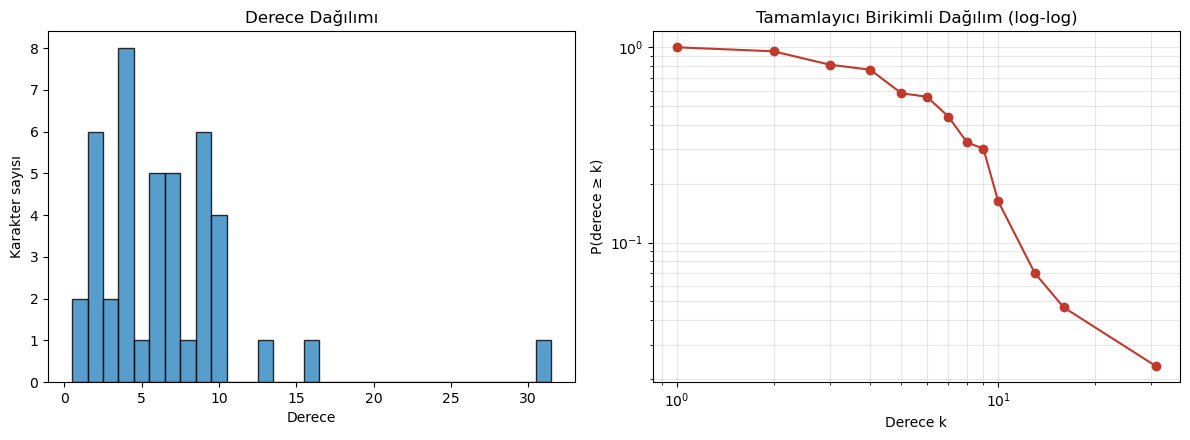

In [14]:
P.plot_degree_distribution(G);

In [15]:
pd.Series(M.small_world_analysis(G), name="Değer").to_frame()

,Değer
C,0.632
L,2.185
C_random,0.158
L_random,2.155
sigma,3.941


`sigma = (C/C_rand) / (L/L_rand)`. sigma > 1 ise ağ, rastgele ağa yakın ortalama yol uzunluğunu
korurken çok daha yüksek kümelenmeye sahiptir (**small-world**).

## 7. İşaretli ağ: Heider yapısal denge teorisi

In [16]:
bal = M.structural_balance(G)
print({k: v for k, v in bal.items() if k != "unbalanced_triangles"})
print("Dengesiz üçgenler:")
for t in bal["unbalanced_triangles"]:
    print("  ", t)

{'triangles': 172, 'balanced': 156, 'unbalanced': 16, 'balance_ratio': 0.9069767441860465}
Dengesiz üçgenler:
   ('Harry', 'Ron', 'Peter Pettigrew')
   ('Harry', 'Dumbledore', 'Snape')
   ('Harry', 'Dumbledore', 'Quirrell')
   ('Harry', 'James Potter', 'Peter Pettigrew')
   ('Harry', 'Lily Potter', 'Snape')
   ('Harry', 'Draco', 'Narcissa Malfoy')
   ('Harry', 'Snape', 'Narcissa Malfoy')
   ('Harry', 'Voldemort', 'Narcissa Malfoy')
   ('Harry', 'Bellatrix', 'Narcissa Malfoy')
   ('Harry', 'Lucius Malfoy', 'Narcissa Malfoy')
   ('Dumbledore', 'Sirius', 'Snape')
   ('Sirius', 'James Potter', 'Peter Pettigrew')
   ('Remus Lupin', 'James Potter', 'Peter Pettigrew')
   ('James Potter', 'Lily Potter', 'Snape')
   ('James Potter', 'Peter Pettigrew', 'Voldemort')
   ('Bellatrix', 'Narcissa Malfoy', 'Tonks')


Üçgenlerin büyük çoğunluğu dengelidir ("dostumun dostu dostumdur, düşmanımın düşmanı dostumdur").
Dengesiz olanlar hikâyedeki çelişkili karakterlere (Snape: Dumbledore'un müttefiki, Harry'nin düşmanı; Pettigrew: Potter'ların dostu ama hain; Narcissa: Ölüm Yiyen ailesinden olup Harry'ye yalan söyleyerek yardım eden) denk gelir.